In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
os.makedirs("../report/figures", exist_ok=True)

df = pd.read_csv("C:\\Users\\Nico\\Documents\\The Power MBA\\Proyecto Final\\cs2-pro-scene-analysis\\data\\processed\\cs2_final_dataset.csv", parse_dates=["datetime"])
print(df.shape)
print(df["datetime"].min().date(), "->", df["datetime"].max().date())
print({"partidas": df["match_id"].nunique(), "mapas": df["game_id"].nunique(),
       "jugadores": df["player_id"].nunique(), "equipos": df["team_id"].nunique(),
       "torneos": df["tournament"].nunique()})
print(df.groupby("tier").agg(filas=("player_id", "size"), mapas=("game_id", "nunique")))

(119105, 48)
2023-10-25 -> 2026-10-31
{'partidas': 5974, 'mapas': 12400, 'jugadores': 1339, 'equipos': 11835, 'torneos': 332}
      filas  mapas
tier              
1     75030   7667
2     39629   4251
3      4446    482


In [2]:
num = ["kills", "deaths", "assists", "adr", "kast"]
print(df[num].describe().round(2).T)
print(df[num].skew().round(2))

            count   mean    std  min   25%   50%   75%    max
kills    119105.0  14.39   5.51  0.0  11.0  14.0  18.0   67.0
deaths   119105.0  14.42   4.26  0.0  12.0  14.0  17.0   55.0
assists  119105.0   4.99   2.75  0.0   3.0   5.0   7.0   28.0
adr      119105.0  72.76  19.20  0.4  59.6  71.7  84.7  186.4
kast     119105.0  71.63  11.97  0.0  64.3  72.2  80.0  100.0
kills      0.70
deaths     0.72
assists    0.83
adr        0.38
kast      -0.37
dtype: float64


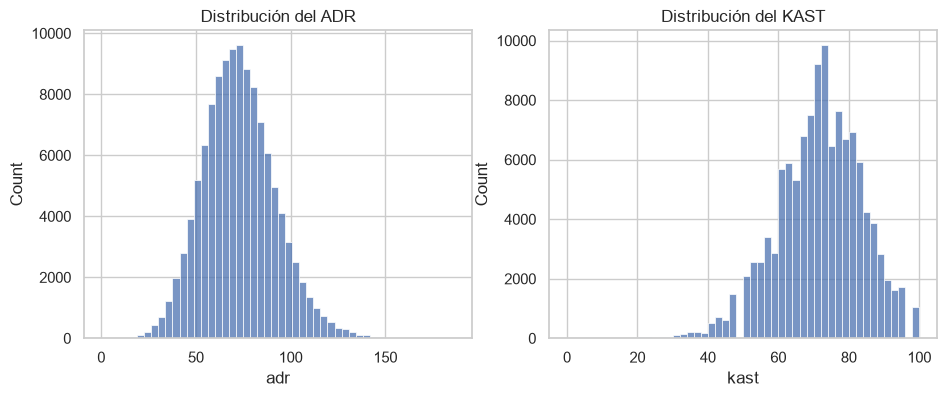

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["adr"], bins=50, ax=ax[0]); ax[0].set_title("Distribución del ADR")
sns.histplot(df["kast"], bins=50, ax=ax[1]); ax[1].set_title("Distribución del KAST")
fig.savefig("../report/figures/01_dist_adr_kast.png", dpi=120, bbox_inches="tight")
plt.show()

          kills  deaths  assists    adr   kast
Derrota   12.87   15.98     4.44  66.41  65.24
Victoria  15.88   12.89     5.52  78.96  77.88


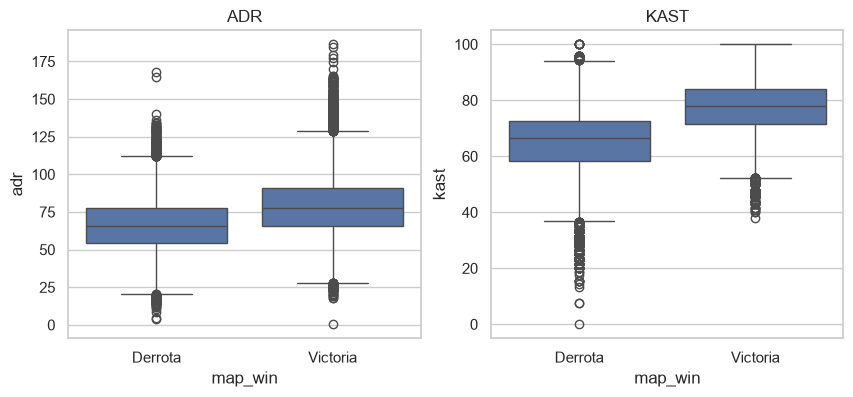

In [4]:
res = df.groupby("map_win")[num].mean().round(2)
res.index = ["Derrota", "Victoria"]
print(res)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x="map_win", y="adr", ax=ax[0]); ax[0].set_xticks([0, 1], ["Derrota", "Victoria"]); ax[0].set_title("ADR")
sns.boxplot(data=df, x="map_win", y="kast", ax=ax[1]); ax[1].set_xticks([0, 1], ["Derrota", "Victoria"]); ax[1].set_title("KAST")
fig.savefig("../report/figures/02_victoria_vs_derrota.png", dpi=120, bbox_inches="tight")
plt.show()

In [5]:
print(df.groupby("tier")[num + ["total_rounds"]].mean().round(2))

      kills  deaths  assists    adr   kast  total_rounds
tier                                                    
1     14.30   14.36     5.00  72.41  71.62         21.73
2     14.55   14.53     4.95  73.32  71.62         21.78
3     14.54   14.42     5.00  73.73  71.93         21.55


map_name
Ancient        2131
Mirage         2121
Nuke           1783
Dust2          1646
Inferno        1556
Anubis         1387
Overpass        614
Vertigo         547
Train           332
Cache           237
Desconocido      46
Name: count, dtype: int64
map_name  Ancient  Anubis  Cache  Desconocido  Dust2  Inferno  Mirage   Nuke  \
year                                                                           
2023        0.217   0.158  0.000        0.001  0.000    0.111   0.127  0.129   
2024        0.183   0.160  0.000        0.005  0.084    0.122   0.154  0.142   
2025        0.163   0.078  0.000        0.001  0.156    0.147   0.179  0.155   
2026        0.158   0.078  0.066        0.006  0.194    0.111   0.193  0.138   

map_name  Overpass  Train  Vertigo  
year                                
2023         0.149  0.000    0.107  
2024         0.044  0.000    0.107  
2025         0.035  0.086    0.000  
2026         0.052  0.004    0.000  


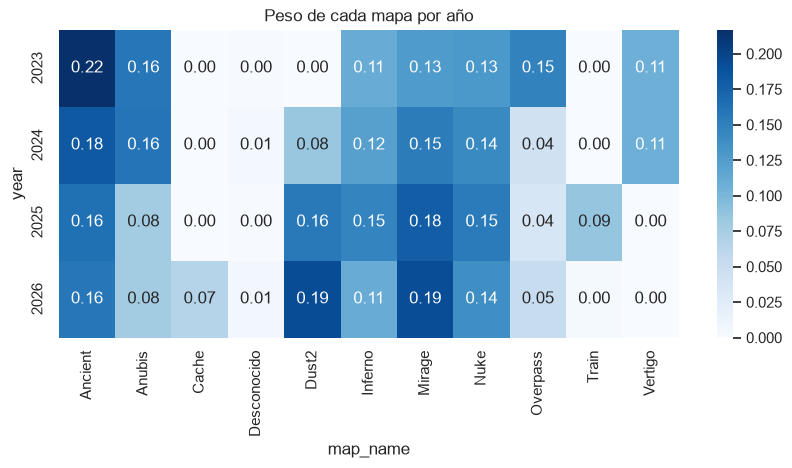

In [6]:
mapas = df.drop_duplicates("game_id")
print(mapas["map_name"].value_counts())

share = pd.crosstab(mapas["year"], mapas["map_name"], normalize="index").round(3)
print(share)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(share, annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Peso de cada mapa por año")
fig.savefig("../report/figures/03_mapas_por_anio.png", dpi=120, bbox_inches="tight")
plt.show()

In [7]:
pais = (df.dropna(subset=["country_code"]).groupby("country_code")
          .agg(jugadores=("player_id", "nunique"), filas=("player_id", "size"),
               adr=("adr", "mean"), kast=("kast", "mean")))
print(pais[pais["filas"] >= 500].sort_values("jugadores", ascending=False).head(10).round(1))

              jugadores  filas   adr  kast
country_code                              
RU                  151  17167  74.1  72.3
BR                  108   9000  71.5  71.5
PL                   65   5545  71.7  70.7
DK                   63   9977  71.5  71.2
US                   60   2918  72.0  69.8
SE                   52   6350  72.2  71.3
UA                   51   7194  73.9  72.6
AU                   35   1494  70.0  69.7
MN                   31   2844  73.6  70.8
FR                   31   4711  73.6  72.3


In [8]:
print(df.groupby("year").agg(filas=("player_id", "size"), adr=("adr", "mean"), kast=("kast", "mean")).round(2))

      filas    adr   kast
year                     
2023   6631  72.60  71.52
2024  41752  73.04  71.70
2025  36096  72.88  71.65
2026  34626  72.34  71.56


In [9]:
jug = (df.groupby(["player_id", "nick"])
         .agg(mapas=("game_id", "nunique"), adr=("adr", "mean"), kast=("kast", "mean"), win=("map_win", "mean"))
         .reset_index())
reg = jug[jug["mapas"] >= 100]
print(len(reg), "jugadores con 100+ mapas de", len(jug))
print(reg.sort_values("adr", ascending=False).head(10).round(2))

393 jugadores con 100+ mapas de 1339
      player_id      nick  mapas    adr   kast   win
806        4710      Donk    483  96.43  76.98  0.69
154         550     ZywOo    506  87.97  77.96  0.71
1157      26434  Kyousuke    329  87.19  74.63  0.63
391        1644   nEMANHA    239  85.78  70.96  0.51
141         495    blameF    346  84.52  76.47  0.48
1116      25560      Dawy    121  84.22  74.43  0.52
796        4574    insani    312  83.74  72.30  0.49
61          156  XANTARES    505  83.35  73.74  0.57
877        5420  Magnojez    337  82.69  72.06  0.58
47          135     jkaem    176  82.42  70.84  0.46


In [10]:
for col in ["adr", "kast"]:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col}: límites {lo:.1f}-{hi:.1f} | outliers {n} ({n/len(df):.1%})")

print("KAST < 20:", (df["kast"] < 20).sum(), "| ADR > 150:", (df["adr"] > 150).sum())
print(df.loc[df["kast"] < 20, ["total_rounds", "kills", "deaths", "adr", "kast"]].describe().round(1))

adr: límites 21.9-122.4 | outliers 1455 (1.2%)
kast: límites 40.7-103.6 | outliers 1325 (1.1%)
KAST < 20: 13 | ADR > 150: 76
       total_rounds  kills  deaths   adr  kast
count          13.0   13.0    13.0  13.0  13.0
mean           14.0    1.3    13.5  19.4  13.5
std             1.5    1.4     0.8   8.3   5.3
min            13.0    0.0    13.0   3.9   0.0
25%            13.0    0.0    13.0  14.3  13.3
50%            13.0    1.0    13.0  21.5  15.4
75%            15.0    2.0    14.0  25.7  15.4
max            17.0    4.0    15.0  30.9  18.8
